# Hydrogen Flame Kinetics: Active Subspaces of the 31-Parameter Prior of a Bayesian Calibration

__John Bell__, Computational Research Division, Lawrence Berkeley National Lab, Berkeley, CA 94720, USA

__Marcus Day__, Computational Research Division, Lawrence Berkeley National Lab, Berkeley, CA 94720, USA

__Jonathan Goodman__, Courant Institute of Mathematical Sciences, New York University, New York, NY 10012, USA

__Ray Grout__, Computational Science Center, National Renewable Energy Laboratory, Golden, CO 80401, USA

__Matthias Morzfeld__, Department of Mathematics, University of Arizona, Tucson, AZ, 85721, USA

Notebook: Claude (Anthropic) for P. Constantine, 2026

<br>

The notebook runs in Python 3 with numpy, matplotlib and the [active_subspaces](https://github.com/paulcon/active_subspaces) library (version 1.0 or later) and reads the shipped data files. In the repository's terms this is a **stored-data** set: the data were computed for this repository with [Cantera](https://cantera.org) 3.2.0, an outside code, through `h2_flame_driver.py` and `generate_data.py` (see `DATA.md`). The driver's constants (names, Table 1 values, bounds, prior moments) import without Cantera; solving the model needs it. The paper was read in its arXiv version (arXiv:1803.03500v1); page numbers below refer to that preprint.

In [1]:
%matplotlib inline
import time
import warnings

import numpy as np
import matplotlib.pyplot as plt
import active_subspaces as ac
import h2_flame_driver as hd   # names, Table 1 values, bounds, prior moments (numpy only); solving needs Cantera

SEED = 2019                    # the only seed in this notebook (bootstrap)
t_start = time.perf_counter()
QOIS = ['tau', 'Su1', 'Su20']
QLAB = {'tau': r'$\ln\tau$', 'Su1': r'$\ln S_{u,1}$', 'Su20': r'$\ln S_{u,20}$'}
QUNIT = {'tau': 's', 'Su1': 'm/s', 'Su20': 'm/s'}
SHORT = [n.replace('_eff_', ' ε ').replace('_A0', ' A0').replace('_Ainf', ' A∞').replace('_A', ' A')
         for n in hd.NAMES]

### Summary

Bell et al. calibrate 31 pre-exponential factors and third-body efficiencies of the HO$_2$ and H$_2$O$_2$ reactions of a hydrogen mechanism against 91 flame-speed, flow-reactor and ignition experiments, starting from broad truncated-Gaussian priors (pp. 5–6). Here 500 Monte Carlo draws from that prior are run through Cantera for one ignition delay and two laminar flame speeds, with finite-difference gradients, at conditions chosen for this data set. The ignition delay and the lean 20 atm flame speed each have one dominant direction, led by the low-pressure rate of H + O$_2$ (+M) ⇌ HO$_2$ (+M), while the stoichiometric 1 atm flame speed has a two-dimensional active subspace (λ2/λ3 = 9.6, bootstrap interval [8.6, 11.1]): that rate, and the branching HO$_2$ + H → 2 OH against HO$_2$ + H → H$_2$ + O$_2$; its first eigenvalue is set by a handful of samples with the rate near zero.

### Active subspaces in brief

For a function $f(\mathbf x)$ of $m$ inputs with density $\rho$, the active subspace is spanned by the leading eigenvectors of $\mathbf C = \int \nabla f\,\nabla f^T \rho\,d\mathbf x = \mathbf W\Lambda\mathbf W^T$. If the first $n$ eigenvalues are much larger than the rest, $f$ varies mostly along the active variables $\mathbf y = \mathbf W_1^T\mathbf x$: a plot of $f$ against $\mathbf y$ (a *sufficient summary plot*) shows the main trend, and a low-degree polynomial in $\mathbf y$ can stand in for $f$. We estimate $\mathbf C$ by the sample average of gradient outer products and assess it with the bootstrap. See P. G. Constantine, [*Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*](https://doi.org/10.1137/1.9781611973860), SIAM, 2015.

### The model

**Kinetics.** The mechanism is that of Burke et al. [2] (11 species here) plus reactions X1 (HO$_2$ + H → H$_2$O + O) and X6 (O + OH + M → HO$_2$ + M) from You et al. [3], as summarized in the paper's Table 1 (p. 6). Forward rate constants are $K_f = A T^{\beta}\exp(-E_a/RT)$ (Table 1 caption); reverse rates follow from equilibrium constants. A three-body reaction has rate $K_f[\mathrm M]$ with $[\mathrm M] = \sum_k \varepsilon_k C_k$, where $\varepsilon_k$ is the efficiency of species $k$ (1 unless listed). The falloff reactions R9 (H + O$_2$ (+M) ⇌ HO$_2$ (+M)) and R15 (H$_2$O$_2$ (+M) ⇌ 2 OH (+M)) use the Troe form with the printed $F_c$ (0.5 and 0.43):
$$
k = k_\infty \frac{P_r}{1+P_r}\,F,\qquad P_r = \frac{k_0[\mathrm M]}{k_\infty},\qquad
\log_{10}F = \frac{\log_{10}F_c}{1+\left(\dfrac{\log_{10}P_r + c}{N - 0.14(\log_{10}P_r + c)}\right)^2},
$$
$c = -0.4 - 0.67\log_{10}F_c$, $N = 0.75 - 1.27\log_{10}F_c$ (Cantera's Troe falloff; the paper names it, "TROE: Fc", Table 1).

**Inputs.** The 31 calibration parameters are the pre-exponential factors and third-body efficiencies of the HO$_2$ and H$_2$O$_2$ reactions marked in red and green in Table 1 (p. 6; Sec. 2.2, p. 5); the two green entries, the Ar and He efficiencies of X6, are one parameter. Each has a Gaussian prior with mean equal to its Table 1 value and standard deviation equal to the mean, truncated to the bounds $L{:}U$ of Table 1 (Sec. 2.2, p. 5; Table 1, p. 6). The high- and low-pressure limits of R9 and R15 have separate A factors, and the two expressions of R14 and of H$_2$O$_2$ + OH ⇌ HO$_2$ + H$_2$O are separate inputs. Each A multiplies its own Arrhenius expression only. All other rate parameters keep their Table 1 values.

**Quantities of interest.** The paper conditions on 91 experiments: 77 laminar premixed flame speeds, 6 flow reactors and 8 ignition delays (Sec. 2.3, p. 5). It does not list their conditions, which are in its refs. [16] and [3] (Burke et al. [2] and Davis et al. [4] here); those were not consulted here. We therefore choose three conditions of the same kinds; the choices are this data set's, except where a page is given:

| QoI | definition | conditions | source |
|---|---|---|---|
| $\tau$ (s) | ignition delay of a constant-volume reactor (the paper simulates ignition experiments at constant volume, p. 5): first time $T$ reaches $T_0 + (T_{eq} - T_0)/2$, $T_{eq}$ the adiabatic constant-volume equilibrium temperature | H$_2$:O$_2$:Ar = 2:1:97, $T_0$ = 1100 K, $P_0$ = 2 atm | this data set's choice (a dilute Ar mixture of the kind used in shock tubes) |
| $S_{u,1}$ (m/s) | speed of a steady, unstrained, adiabatic premixed flame ("the propagation speed of the steady, unstrained flame", p. 5) | H$_2$/air, $\phi$ = 1, 1 atm, 298 K | this data set's choice |
| $S_{u,20}$ (m/s) | as $S_{u,1}$ | H$_2$/air, $\phi$ = 0.4, 20 atm, 298 K | mixture and pressure of the paper's 2-D flame kernel (p. 11); the unburned temperature is not stated there, and 298 K is assumed |

The flames are solved with Cantera's `FreeFlame` (mixture-averaged transport, no Soret term; grid criteria ratio 2, slope 0.02, curve 0.04) instead of the paper's PREMIX; the reactor with CVODES instead of VODE. The table below is printed from the driver's constants (Table 1, p. 6); the prior mean and sd are those of the truncated distribution.

In [2]:
print(f"{'#':>2s} {'input':13s} {'units':13s} {'Table 1':>10s} {'L':>8s} {'U':>8s} "
      f"{'prior mean':>11s} {'prior sd':>10s} {'sd/value':>8s}")
for k, (n, u) in enumerate(zip(hd.NAMES, hd.UNITS)):
    print(f'{k + 1:2d} {n:13s} {u:13s} {hd.NOMINAL[k]:10.4g} {hd.LOWER[k]:8.2g} {hd.UPPER[k]:8.2g} '
          f'{hd.PRIOR_MEAN[k]:11.4g} {hd.PRIOR_SD[k]:10.4g} {hd.PRIOR_SD[k] / hd.NOMINAL[k]:8.3f}')
out = np.where((hd.NOMINAL < hd.LOWER) | (hd.NOMINAL > hd.UPPER))[0]
print(f'\nm = {len(hd.NAMES)} inputs; Table 1 values outside their own bounds L:U: '
      + ', '.join(f'{hd.NAMES[k]} ({hd.NOMINAL[k]:.3g} not in [{hd.LOWER[k]:.3g}, {hd.UPPER[k]:.3g}])' for k in out))
print('conditions:', hd.IGNITION, {c: {k: v for k, v in d.items() if k != 'width'} for c, d in hd.FLAMES.items()})

 # input         units            Table 1        L        U  prior mean   prior sd sd/value
 1 R9_Ainf       cm^3/mol/s     4.651e+12    2e+12    1e+13     5.7e+12  2.186e+12    0.470
 2 R9_A0         cm^6/mol^2/s   6.366e+20        0    8e+20   4.294e+20  2.238e+20    0.352
 3 R9_eff_H2     -                      2        0        6       2.459      1.442    0.721
 4 R9_eff_H2O    -                     14        0       28          14      7.554    0.540
 5 R9_eff_O2     -                   0.78        0        3      0.9985      0.609    0.781
 6 R9_eff_Ar     -                   0.67        0        3       0.862     0.5302    0.791
 7 R9_eff_He     -                    0.8        0        3       1.022     0.6219    0.777
 8 R10_A         cm^3/mol/s      2.75e+06    1e+06    5e+16   3.965e+06   1.99e+06    0.724
 9 R11_A         cm^3/mol/s     7.079e+13    2e+13    1e+14    6.11e+13  2.259e+13    0.319
10 R12_A         cm^3/mol/s      2.85e+10    1e+09    1e+11   3.654e+10  2.163e+

Two features of Table 1 show in the printout: the Table 1 value of `R15_Ainf` (2.00e12) lies outside its own bounds 5e11:1e12, so every prior draw lies below it; and because sd = mean, the truncation at 0 keeps much of the prior mass of the efficiencies and of `R9_A0` close to zero. Neither is changed here: the prior is that of the paper as printed.

### Load data

`generate_data.py` drew 500 independent Monte Carlo samples from the prior (inverse-CDF transform of uniforms, seed 2019452), rounded them to the written digits, and ran the Cantera model at each. The files hold the physical inputs; $\tau$, $S_{u,1}$ and $S_{u,20}$ with a status flag each (0 solved, 1 solved on the retry from the nominal flame, 2 failed and stored as NaN); and the gradients with respect to the physical inputs: central differences for $\tau$ (step $10^{-3}$ of each prior sd), and central finite differences on the fixed grid of each flame for $S_{u,1}$ and $S_{u,20}$ (step $10^{-3}$ of each prior sd, at most 2 % of an A factor). Cantera's discrete adjoint is not used: for these flames it is too small by a row-dependent factor (`DATA.md`, "Accuracy"). `nominal.csv` and `nominal_gradients.csv` hold the same at the Table 1 values.

In [3]:
X = np.loadtxt('inputs.csv', delimiter=',')            # (500, 31) physical inputs, order of Table 1
F = np.loadtxt('outputs.csv', delimiter=',')           # (500, 6): tau [s], Su1 [m/s], Su20 [m/s], 3 status flags
G = {q: np.loadtxt(f'gradients_{q}.csv', delimiter=',') for q in QOIS}   # (500, 31) each, physical units
nom = np.loadtxt('nominal.csv', delimiter=',')          # (3,) the QoIs at the Table 1 values
Gnom = np.loadtxt('nominal_gradients.csv', delimiter=',')   # (3, 31) their gradients
for n, a in [('X', X), ('F', F)] + [(f'G[{q}]', G[q]) for q in QOIS] + [('nom', nom), ('Gnom', Gnom)]:
    print(f'{n:9s} {a.shape}')

X         (500, 31)
F         (500, 6)
G[tau]    (500, 31)
G[Su1]    (500, 31)
G[Su20]   (500, 31)
nom       (3,)
Gnom      (3, 31)


We count failed solves, check the samples against the bounds and the prior moments, and print the range of each QoI. Rows are dropped only by the stored status flags (rule: a row is kept when all three solves succeeded).

In [4]:
val = {q: F[:, j] for j, q in enumerate(QOIS)}
status = {q: F[:, 3 + j].astype(int) for j, q in enumerate(QOIS)}
for q in QOIS:
    c = np.bincount(status[q], minlength=3)
    print(f'{q:5s}: status 0 (solved) {c[0]}, 1 (solved on retry) {c[1]}, 2 (failed, NaN) {c[2]}; '
          f'NaN values {np.isnan(val[q]).sum()}')
ok = np.all([status[q] < 2 for q in QOIS], axis=0)     # rule: keep a row only if all three solves succeeded
print(f'rows kept for the analysis: {ok.sum()} of {len(ok)}')
inside = np.all((X >= hd.LOWER) & (X <= hd.UPPER), axis=1)
print(f'rows inside the bounds L:U (all inputs >= 0): {inside.sum()} of {len(X)}; duplicate rows '
      f'{len(X) - len(np.unique(X, axis=0))}; R15_Ainf below its Table 1 value in {np.sum(X[:, 13] < hd.NOMINAL[13])} rows')
Z = (X - hd.PRIOR_MEAN) / hd.PRIOR_SD                    # the scaling used below: each input by its prior sd
print(f'standardized inputs: sample means {Z.mean(0).min():+.3f} to {Z.mean(0).max():+.3f}, '
      f'sample sds {Z.std(0, ddof=1).min():.3f} to {Z.std(0, ddof=1).max():.3f} (prior: 0 and 1)')
for q in QOIS:
    v = val[q][ok]
    print(f'{q:5s}: min {v.min():.4g}, median {np.median(v):.4g}, max {v.max():.4g} {QUNIT[q]} '
          f'(max/min {v.max() / v.min():.1f}); at the Table 1 values {nom[QOIS.index(q)]:.4g} {QUNIT[q]}')

tau  : status 0 (solved) 500, 1 (solved on retry) 0, 2 (failed, NaN) 0; NaN values 0
Su1  : status 0 (solved) 500, 1 (solved on retry) 0, 2 (failed, NaN) 0; NaN values 0
Su20 : status 0 (solved) 500, 1 (solved on retry) 0, 2 (failed, NaN) 0; NaN values 0
rows kept for the analysis: 500 of 500
rows inside the bounds L:U (all inputs >= 0): 500 of 500; duplicate rows 0; R15_Ainf below its Table 1 value in 500 rows
standardized inputs: sample means -0.070 to +0.089, sample sds 0.952 to 1.064 (prior: 0 and 1)
tau  : min 0.0007457, median 0.0008061, max 0.001605 s (max/min 2.2); at the Table 1 values 0.0008327 s
Su1  : min 1.184, median 2.028, max 2.504 m/s (max/min 2.1); at the Table 1 values 2.276 m/s
Su20 : min 0.002917, median 0.01153, max 0.1523 m/s (max/min 52.2); at the Table 1 values 0.007107 m/s


All 500 rows solved on the first attempt for all three QoIs (status 0 in every row; no retries, no failures), so no row is dropped. The standardized inputs have sample means between −0.070 and +0.089 and sample sds between 0.952 and 1.064, as expected for 500 draws. Su20 spans a factor of 52.2 over the prior (0.002917 to 0.1523 m/s), against factors of 2.2 for τ and 2.1 for Su1; this is why the analysis uses the logarithms of the QoIs.

### Estimate the active subspace

Every row carries a gradient (`DATA.md`, "Accuracy"), so the gradient-based estimator `estimator='as'` is used: $\hat{\mathbf C} = \frac1M\sum_i \nabla_z \ln q_i\,\nabla_z \ln q_i^T$ over the $M$ = 500 prior draws, with $\nabla \ln q = \nabla q / q$. Each input is scaled by its prior standard deviation, $z_j = (x_j - \mu_j)/\sigma_j$ with the mean and sd of the *truncated* prior; `ac.Gaussian` with that mean and diagonal covariance does this scaling (it is a scaling device here; the samples themselves come from the truncated prior, so $\hat{\mathbf C}$ is a Monte Carlo average over the actual prior). The bootstrap uses `nboot = 500` replicates with `SEED`. Signs: the paper shows no eigenvectors, so each eigenvector is oriented so that $\ln q$ increases along it on average (`ac.orient(..., by='mean_gradient')`). As a coordinate check, the least-squares linear fit of $\ln q$ on $\mathbf z$ points in nearly the same direction as the mean scaled gradient (cosines 0.990, 0.970 and 0.994).

In [5]:
space = ac.Gaussian(hd.PRIOR_MEAN, hd.PRIOR_SD**2, names=hd.NAMES)   # used for the scaling only
Xk = X[ok]
fl = {q: np.log(val[q][ok]) for q in QOIS}                    # ln of the QoI
gl = {q: G[q][ok] / val[q][ok, None] for q in QOIS}           # gradient of ln QoI, physical units
for q in QOIS:   # coordinate check: least-squares slope of ln q on Z against the mean scaled gradient
    Zk = space.to_normalized(Xk)
    b = np.linalg.lstsq(np.column_stack([np.ones(len(Zk)), Zk]), fl[q], rcond=None)[0][1:]
    gbar = (gl[q] * hd.PRIOR_SD).mean(0)
    print(f'{q:5s}: cosine(OLS slope, mean scaled gradient) = {b @ gbar / np.linalg.norm(b) / np.linalg.norm(gbar):.3f}')

sub = {}
for q in QOIS:
    s = ac.active_subspace(space=space, X=Xk, f=fl[q], grads=gl[q], estimator='as', n=1,
                           nboot=500, rng=SEED)
    sub[q] = ac.orient(s, by='mean_gradient', grads=gl[q], columns=2)   # sign rule: ln q increases along w_j
    lam = sub[q].eigenvalues
    k_hat = ac.dimension_criterion(sub[q], rule='evg')[2]
    print(f'{q:5s}: lambda1..5 {np.array2string(lam[:5], precision=3)}; lambda1/lambda2 {lam[0] / lam[1]:.1f}, '
          f'lambda2/lambda3 {lam[1] / lam[2]:.1f}, lambda3/lambda4 {lam[2] / lam[3]:.1f}, '
          f'lambda4/lambda5 {lam[3] / lam[4]:.1f}; '
          f'lambda1/trace {lam[0] / lam.sum():.3f}, (lambda1+lambda2)/trace {(lam[0] + lam[1]) / lam.sum():.3f}; '
          f'gap rule picks n = {k_hat}')

tau  : cosine(OLS slope, mean scaled gradient) = 0.990
Su1  : cosine(OLS slope, mean scaled gradient) = 0.970
Su20 : cosine(OLS slope, mean scaled gradient) = 0.994


tau  : lambda1..5 [1.787e-02 9.872e-04 6.419e-04 8.600e-05 6.967e-06]; lambda1/lambda2 18.1, lambda2/lambda3 1.5, lambda3/lambda4 7.5, lambda4/lambda5 12.3; lambda1/trace 0.912, (lambda1+lambda2)/trace 0.962; gap rule picks n = 1


Su1  : lambda1..5 [2.063e-01 4.618e-03 4.798e-04 1.572e-04 1.949e-05]; lambda1/lambda2 44.7, lambda2/lambda3 9.6, lambda3/lambda4 3.1, lambda4/lambda5 8.1; lambda1/trace 0.975, (lambda1+lambda2)/trace 0.997; gap rule picks n = 1


Su20 : lambda1..5 [1.782 0.273 0.137 0.061 0.011]; lambda1/lambda2 6.5, lambda2/lambda3 2.0, lambda3/lambda4 2.2, lambda4/lambda5 5.8; lambda1/trace 0.783, (lambda1+lambda2)/trace 0.903; gap rule picks n = 1


The first eigenvalue dominates for ln τ (λ1/λ2 = 18.1) and ln Su20 (λ1/λ2 = 6.5), carrying 0.912 and 0.783 of the trace, with no comparable second gap (λ2/λ3 = 1.5 and 2.0). For ln Su1 the clearest structure is a second gap, λ2/λ3 = 9.6, and λ1 + λ2 carry 0.997 of the trace; its first ratio, λ1/λ2 = 44.7, is set by the lower tail of the `R9_A0` prior (see "The lower tail of R9_A0" below). The eigenvalue-gap rule picks n = 1 for all three; the dimension used is settled below.

#### Eigenvalues and subspace errors

tau  : lambda1-3 95 % bootstrap intervals [0.0146, 0.0212], [0.00086, 0.00113], [0.000544, 0.000739]; lambda1/lambda2 interval [14.8, 21.9], lambda2/lambda3 interval [1.3, 1.9]; mean distance k = 1, 2, 3, 4: [0.021 0.094 0.049 0.039]; left-out share (sum lambda_2..)/trace 0.088
Su1  : lambda1-3 95 % bootstrap intervals [0.0592, 0.465], [0.0041, 0.00488], [0.000399, 0.000537]; lambda1/lambda2 interval [14.0, 99.9], lambda2/lambda3 interval [8.6, 11.1]; mean distance k = 1, 2, 3, 4: [0.025 0.026 0.049 0.037]; left-out share (sum lambda_2..)/trace 0.025
Su20 : lambda1-3 95 % bootstrap intervals [1.54, 2.03], [0.226, 0.324], [0.0727, 0.224]; lambda1/lambda2 interval [5.5, 7.7], lambda2/lambda3 interval [1.3, 3.7]; mean distance k = 1, 2, 3, 4: [0.029 0.121 0.152 0.041]; left-out share (sum lambda_2..)/trace 0.217


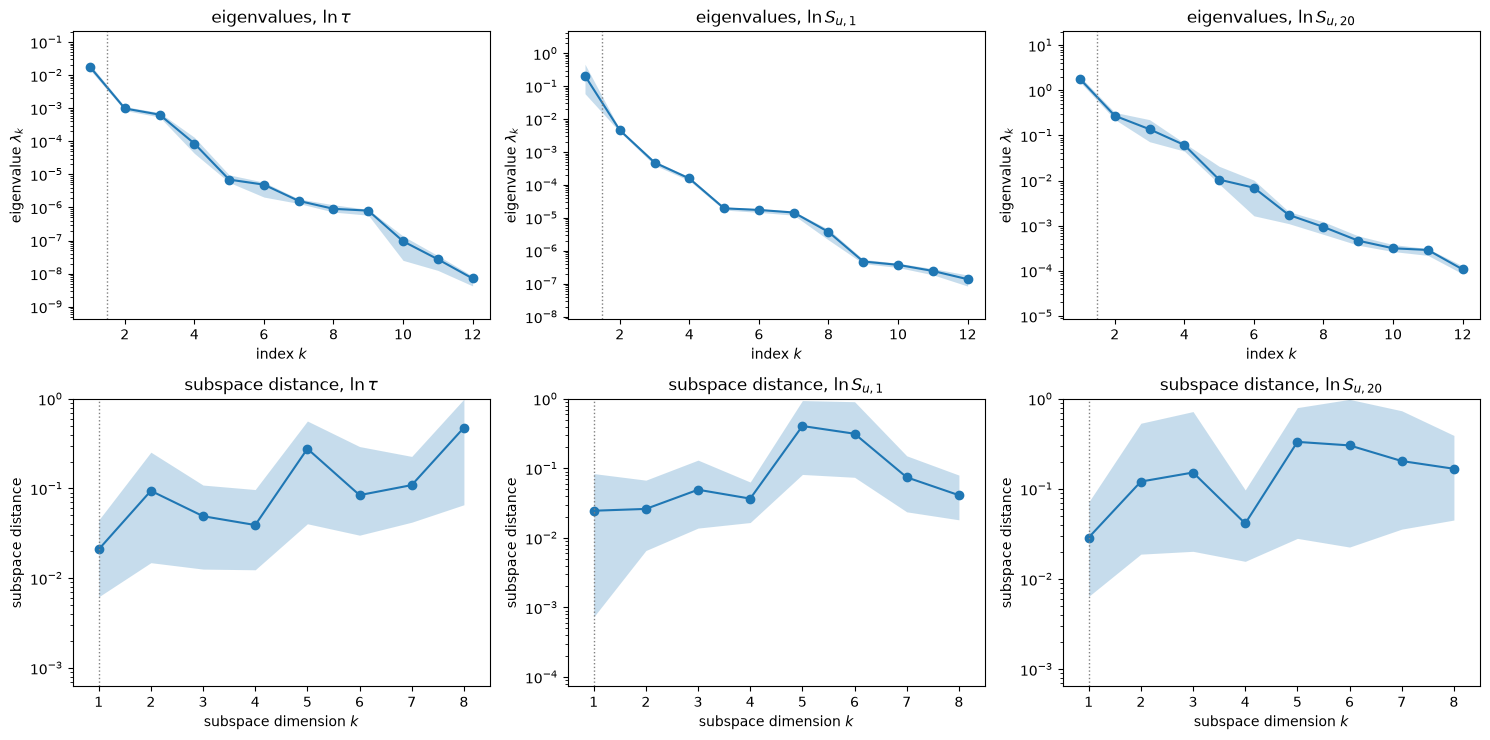

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7.5))
for j, q in enumerate(QOIS):
    ac.plotting.plot_eigenvalues(sub[q], ax=axes[0, j], k_max=12)
    axes[0, j].set_title(f'eigenvalues, {QLAB[q]}')
    ac.plotting.plot_subspace_errors(sub[q], ax=axes[1, j], k_max=8)
    axes[1, j].set_title(f'subspace distance, {QLAB[q]}')
fig.tight_layout(); plt.close(fig)
for q in QOIS:
    lam, B = sub[q].eigenvalues, sub[q].bootstrap_eigenvalues
    lo, hi = np.percentile(B[:, :3], [2.5, 97.5], axis=0)
    r12 = np.percentile(B[:, 0] / B[:, 1], [2.5, 97.5])
    r23 = np.percentile(B[:, 1] / B[:, 2], [2.5, 97.5])
    print(f'{q:5s}: lambda1-3 95 % bootstrap intervals ' + ', '.join(f'[{a:.3g}, {b:.3g}]' for a, b in zip(lo, hi))
          + f'; lambda1/lambda2 interval [{r12[0]:.1f}, {r12[1]:.1f}], lambda2/lambda3 interval [{r23[0]:.1f}, {r23[1]:.1f}]'
          + '; mean distance k = 1, 2, 3, 4: '
          + np.array2string(sub[q].bootstrap_distances.mean(0)[:4], precision=3)
          + f'; left-out share (sum lambda_2..)/trace {lam[1:].sum() / lam.sum():.3f}')
fig

For ln τ the bootstrap interval of λ1 is narrow ([0.0146, 0.0212]) and λ1/λ2 lies in [14.8, 21.9]; for ln Su20 λ1 lies in [1.54, 2.03] and λ1/λ2 in [5.5, 7.7]. For ln Su1 the intervals of λ2 and λ3 are separated ([0.0041, 0.00488] against [0.000399, 0.000537]) and λ2/λ3 lies in [8.6, 11.1], while λ1 is poorly determined, [0.0592, 0.465], and λ1/λ2 ranges over [14.0, 99.9]. The one-dimensional subspace is stable for all three: mean bootstrap distances 0.021, 0.025 and 0.029 at k = 1. At k = 2 the distance is 0.026 for ln Su1 but 0.094 and 0.121 for ln τ and ln Su20, whose second eigenvalue is not separated from the third. The left-out share of the trace at n = 1 is 0.088, 0.025 and 0.217. The wide λ1 interval of ln Su1 is explained in "The lower tail of R9_A0" below.

In [7]:
# a null reference: the spectrum of M = 500 gradient outer products when the gradients carry no
# low-dimensional structure (independent standard normal entries, same M and m)
rng = np.random.default_rng(SEED)
Gn = rng.standard_normal((len(Xk), 31))
lam0 = np.sort(np.linalg.eigvalsh(Gn.T @ Gn / len(Gn)))[::-1]
print(f'unstructured gradients: lambda1/lambda2 = {lam0[0] / lam0[1]:.2f}, lambda1/trace = {lam0[0] / lam0.sum():.3f}')

unstructured gradients: lambda1/lambda2 = 1.05, lambda1/trace = 0.049


For comparison, gradients with no low-dimensional structure (independent standard normal entries, same M and m) give λ1/λ2 = 1.05 and λ1/trace = 0.049, far from the ratios above.

#### Eigenvectors

tau   w1: R9_eff_Ar +0.702, R9_A0 +0.687, R11_A -0.135, R10_A -0.109, R9_eff_H2 +0.042, R12_A +0.032; the other 25 squared components sum to 0.001
      w2: R9_A0 -0.712, R9_eff_Ar +0.651, R10_A -0.250, R9_eff_H2O -0.057, R9_eff_H2 +0.050
Su1   w1: R9_A0 +0.999, R11_A +0.018, R9_eff_H2O +0.016, R10_A -0.015, R9_eff_H2 +0.014, X6_eff_H2O -0.008; the other 25 squared components sum to 0.000
      w2: R11_A +0.722, R10_A -0.510, R9_eff_H2O +0.302, R13_A -0.220, R9_eff_H2 +0.215
Su20  w1: R9_A0 -0.926, R9_eff_H2O -0.346, R13_A -0.103, R14a_A +0.066, R15_A0 +0.047, R12_A -0.041; the other 25 squared components sum to 0.004
      w2: R9_eff_H2O -0.846, R9_A0 +0.372, R15_A0 +0.230, R13_A -0.219, R14a_A +0.167


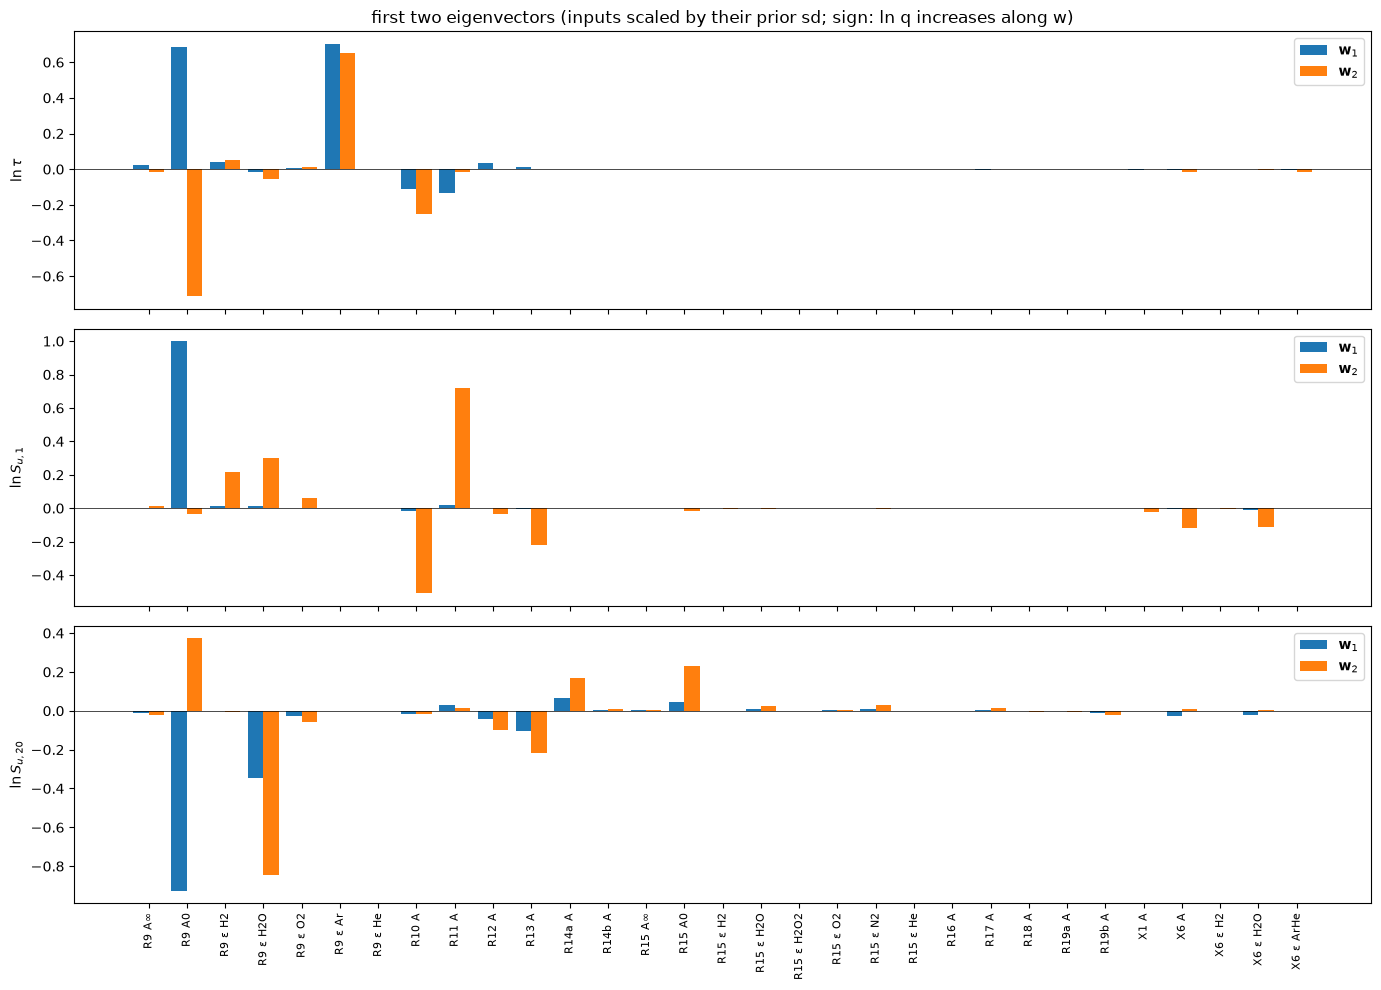

In [8]:
fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)
for j, q in enumerate(QOIS):
    W = sub[q].W
    axes[j].bar(np.arange(31) - 0.2, W[:, 0], width=0.4, label=r'$\mathbf{w}_1$')
    axes[j].bar(np.arange(31) + 0.2, W[:, 1], width=0.4, label=r'$\mathbf{w}_2$')
    axes[j].axhline(0, color='k', lw=0.5); axes[j].set_ylabel(QLAB[q]); axes[j].legend(loc='upper right')
axes[-1].set_xticks(range(31)); axes[-1].set_xticklabels(SHORT, rotation=90, fontsize=8)
axes[0].set_title('first two eigenvectors (inputs scaled by their prior sd; sign: ln q increases along w)')
fig.tight_layout(); plt.close(fig)
for q in QOIS:
    w = sub[q].W[:, 0]
    o = np.argsort(-w**2)
    print(f'{q:5s} w1: ' + ', '.join(f'{hd.NAMES[i]} {w[i]:+.3f}' for i in o[:6])
          + f'; the other {31 - 6} squared components sum to {np.sum(w[o[6:]]**2):.3f}')
    w2 = sub[q].W[:, 1]
    o2 = np.argsort(-w2**2)
    print(f'{"":5s} w2: ' + ', '.join(f'{hd.NAMES[i]} {w2[i]:+.3f}' for i in o2[:5]))
fig

- **ln τ:** $\mathbf w_1$ is led by `R9_eff_Ar` (+0.702) and `R9_A0` (+0.687), then `R11_A` (−0.135) and `R10_A` (−0.109); the other 25 squared components sum to 0.001. The reactor is 97 % argon, so the low-pressure rate of R9 is set by the product of its A factor and the argon efficiency; τ grows with it (chain termination at 1100 K and 2 atm). $\mathbf w_2$ is nearly the contrast of the same two inputs (`R9_A0` −0.712, `R9_eff_Ar` +0.651) with `R10_A` (−0.250).
- **ln Su1:** $\mathbf w_1$ is essentially the `R9_A0` axis (+0.999); at φ = 1 and 1 atm Su1 *increases* with it. $\mathbf w_2$ is led by `R11_A` (+0.722) and `R10_A` (−0.510), then `R9_eff_H2O` (+0.302), `R13_A` (−0.220) and `R9_eff_H2` (+0.215): the branching between HO$_2$ + H → 2 OH (R11) and HO$_2$ + H → H$_2$ + O$_2$ (R10).
- **ln Su20:** $\mathbf w_1$ is led by `R9_A0` with the opposite sign (−0.926) and `R9_eff_H2O` (−0.346), then `R13_A` (−0.103) and `R14a_A` (+0.066); the other 25 squared components sum to 0.004. In the lean 20 atm flame R9 terminates chains, and Su20 falls as its low-pressure rate grows, through its A factor or the collision efficiency of water. $\mathbf w_2$ is led by `R9_eff_H2O` (−0.846) and `R9_A0` (+0.372), then `R15_A0` (+0.230), `R13_A` (−0.219) and `R14a_A` (+0.167).

In [9]:
iR = {n: hd.NAMES.index(n) for n in hd.NAMES}
for q in QOIS:
    w = sub[q].W[:, 0]
    act = ac.activity_scores(sub[q], n=1) / sub[q].eigenvalues.sum()
    print(f'{q:5s}: w1 components R10_A {w[iR["R10_A"]]:+.3f}, R11_A {w[iR["R11_A"]]:+.3f}; '
          f'activity score / trace: R9_Ainf {act[iR["R9_Ainf"]]:.1e}, X1_A {act[iR["X1_A"]]:.1e}, '
          f'largest {hd.NAMES[np.argmax(act)]} {act.max():.3f}')
for a, b in [('tau', 'Su1'), ('tau', 'Su20'), ('Su1', 'Su20')]:
    print(f'|w1({a}) . w1({b})| = {abs(sub[a].W[:, 0] @ sub[b].W[:, 0]):.3f}')
# local (Table 1 values) against global directions
for j, q in enumerate(QOIS):
    gn = Gnom[j] / nom[j] * hd.PRIOR_SD
    print(f'{q:5s}: |cos(scaled gradient at the Table 1 values, w1)| = {abs(gn @ sub[q].W[:, 0]) / np.linalg.norm(gn):.3f}')

tau  : w1 components R10_A -0.109, R11_A -0.135; activity score / trace: R9_Ainf 4.4e-04, X1_A 2.4e-05, largest R9_eff_Ar 0.450
Su1  : w1 components R10_A -0.015, R11_A +0.018; activity score / trace: R9_Ainf 3.4e-07, X1_A 9.2e-07, largest R9_A0 0.974
Su20 : w1 components R10_A -0.016, R11_A +0.030; activity score / trace: R9_Ainf 1.4e-04, X1_A 1.5e-06, largest R9_A0 0.672
|w1(tau) . w1(Su1)| = 0.687
|w1(tau) . w1(Su20)| = 0.637
|w1(Su1) . w1(Su20)| = 0.929
tau  : |cos(scaled gradient at the Table 1 values, w1)| = 0.932
Su1  : |cos(scaled gradient at the Table 1 values, w1)| = 0.508
Su20 : |cos(scaled gradient at the Table 1 values, w1)| = 0.687


The activity scores (n = 1, divided by the trace) are largest for `R9_eff_Ar` (0.450) for ln τ and for `R9_A0` for the flame speeds (0.974 and 0.672). The two flame speeds share much of their first direction up to sign (|w1(Su1)·w1(Su20)| = 0.929), while ln τ's makes inner products 0.687 and 0.637 with them. The gradient at the Table 1 values is a fair guide for ln τ (|cosine| with $\mathbf w_1$ 0.932) but not for the flame speeds (0.508 and 0.687): a local sensitivity analysis at the nominal point would miss the global direction.

#### Sufficient summary plots

tau  : LOO R^2 of polynomials in y1, degree 1, 2, 3: 0.6874, 0.9182, 0.9409
Su1  : LOO R^2 of polynomials in y1, degree 1, 2, 3: 0.5699, 0.6972, 0.7425
Su20 : LOO R^2 of polynomials in y1, degree 1, 2, 3: 0.8192, 0.8788, 0.8781


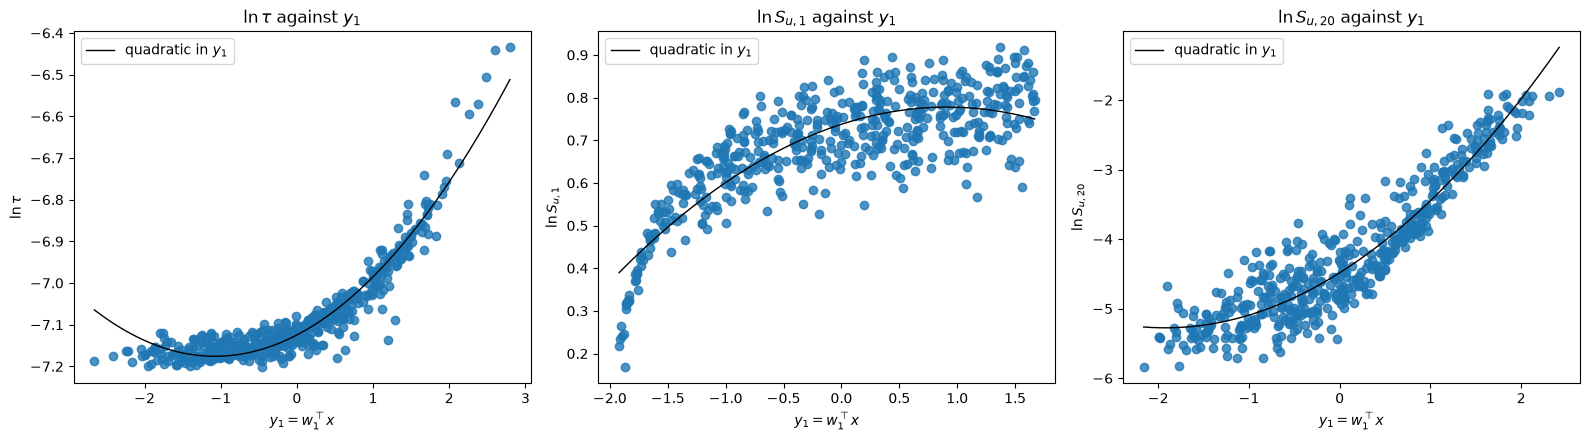

In [10]:
sur = {}
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for j, q in enumerate(QOIS):
    y = space.to_normalized(Xk) @ sub[q].W[:, 0]
    sur[q] = {d: ac.fit_surrogate(X=Xk, f=fl[q], subspace=sub[q], kind='poly', degree=d) for d in (1, 2, 3)}
    ac.plotting.plot_sufficient_summary(sub[q], X=Xk, f=fl[q], dims=1, qoi_label=QLAB[q], ax=axes[j])
    yy = np.linspace(y.min(), y.max(), 200)
    axes[j].plot(yy, sur[q][2].evaluate(yy[:, None]), 'k-', lw=1, label='quadratic in $y_1$')
    axes[j].legend(); axes[j].set_title(f'{QLAB[q]} against $y_1$')
fig.tight_layout(); plt.close(fig)
for q in QOIS:
    print(f'{q:5s}: LOO R^2 of polynomials in y1, degree 1, 2, 3: '
          + ', '.join(f'{sur[q][d].loo_r_squared:.4f}' for d in (1, 2, 3)))
fig

ln τ is a smooth, convex function of $y_1$; a quadratic in $y_1$ reaches LOO R² 0.9182 (linear 0.6874, cubic 0.9409). ln Su20 rises with $y_1$, more steeply at large $y_1$; the quadratic gives LOO R² 0.8788 (linear 0.8192, cubic 0.8781). ln Su1 has more scatter about its one-dimensional trend: the quadratic in $y_1$ gives LOO R² 0.6972 and the cubic 0.7425; it rises steeply at the low end of $y_1$, where `R9_A0` approaches zero.

tau  : LOO R^2 of a quadratic in (y1, y2): 0.9471
Su1  : LOO R^2 of a quadratic in (y1, y2): 0.9266
Su20 : LOO R^2 of a quadratic in (y1, y2): 0.9362


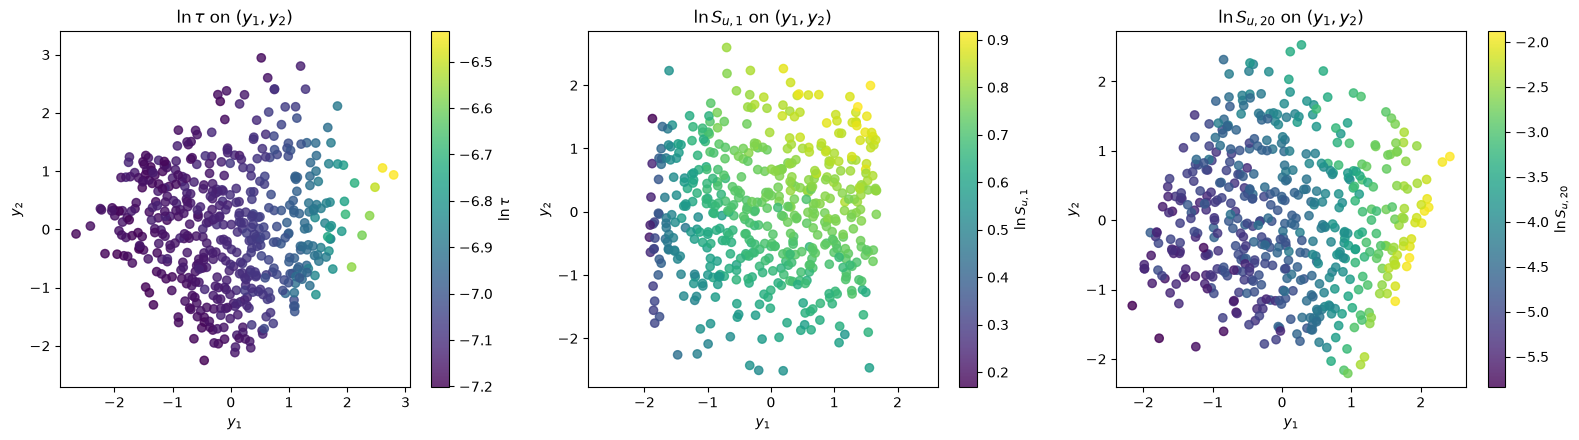

In [11]:
sub2, sur2 = {}, {}
for q in QOIS:
    s2 = ac.active_subspace(space=space, X=Xk, f=fl[q], grads=gl[q], estimator='as', n=2)
    sub2[q] = ac.orient(s2, by='mean_gradient', grads=gl[q])
    sur2[q] = ac.fit_surrogate(X=Xk, f=fl[q], subspace=sub2[q], kind='poly', degree=2)
    print(f'{q:5s}: LOO R^2 of a quadratic in (y1, y2): {sur2[q].loo_r_squared:.4f}')
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for j, q in enumerate(QOIS):
    ac.plotting.plot_sufficient_summary(sub2[q], X=Xk, f=fl[q], dims=2, qoi_label=QLAB[q], ax=axes[j])
    axes[j].set_title(f'{QLAB[q]} on $(y_1, y_2)$')
fig.tight_layout(); plt.close(fig)
fig

A quadratic in $(y_1, y_2)$ raises LOO R² to 0.9471 for ln τ, 0.9266 for ln Su1 and 0.9362 for ln Su20. For ln Su1 the second direction is well determined (distance 0.026 at k = 2, λ2/λ3 = 9.6); for ln τ and ln Su20 it is not (distances 0.094 and 0.121, λ2/λ3 = 1.5 and 2.0), so their gain comes from a direction that the bootstrap does not pin down.

#### The lower tail of R9_A0

The prior of `R9_A0` is a Gaussian of mean and sd 6.366e20 truncated to [0, 8e20], so it puts appreciable mass on values near zero, i.e. on mechanisms in which the low-pressure H + O$_2$ + M recombination is nearly absent. Su1 changes steeply there. To see how much this tail drives the estimates, the analysis is repeated on the rows with `R9_A0` ≥ c × (Table 1 value), c = 0.05, 0.1 and 0.2. This is this data set's check, not part of the paper. Because the prior is a product of independent factors, these rows are exactly a sample of the prior with the lower bound of `R9_A0` raised to c × 6.366e20.

In [12]:
# sensitivity to the lower tail of R9_A0: the prior conditioned on R9_A0 >= c * (Table 1 value) is the
# same truncated Gaussian with its lower bound raised from 0 to c * 6.366e20, and its samples are exactly
# the rows that satisfy the condition, so no reweighting is needed (this data set's check, not the paper's)
iA0 = hd.NAMES.index('R9_A0')
r0 = Xk[:, iA0] / hd.NOMINAL[iA0]
print(f'rows with R9_A0 below 0.01, 0.05, 0.1, 0.2 of its Table 1 value: '
      + ', '.join(str(int(np.sum(r0 < c))) for c in (0.01, 0.05, 0.1, 0.2)) + f' of {len(r0)}')
for q in QOIS:
    s = (gl[q] * hd.PRIOR_SD)**2
    top = np.argsort(-s.sum(1))[:5]
    print(f'{q:5s}: the 5 rows with the largest squared scaled gradient carry {s[top].sum() / s.sum():.3f} of the trace; '
          f'their R9_A0 / Table 1 value: ' + ', '.join(f'{v:.3g}' for v in r0[top]))
# the (R9_A0, R9_A0) entry of C for ln Su1, split by the value of R9_A0, against the prior mass of each range
a0 = (hd.LOWER[iA0] - hd.NOMINAL[iA0]) / hd.NOMINAL[iA0]
b0 = (hd.UPPER[iA0] - hd.NOMINAL[iA0]) / hd.NOMINAL[iA0]
cdf = lambda c: (hd._Phi(c - 1.0) - hd._Phi(a0)) / (hd._Phi(b0) - hd._Phi(a0))   # prior CDF of R9_A0 / Table 1 value
dA0 = (gl['Su1'][:, iA0] * hd.PRIOR_SD[iA0])**2
C11 = dA0.mean()
print(f'ln Su1: (R9_A0, R9_A0) entry of C {C11:.4f} (lambda1 {sub["Su1"].eigenvalues[0]:.4f})')
for lo_, hi_ in ((0.0, 0.01), (0.01, 0.1), (0.1, np.inf)):
    sel = (r0 >= lo_) & (r0 < hi_)
    mass = cdf(min(hi_, hd.UPPER[iA0] / hd.NOMINAL[iA0])) - cdf(lo_)
    print(f'  R9_A0 / Table 1 value in [{lo_:g}, {hi_:g}): prior mass {mass:.4f} ({mass * len(r0):.1f} of {len(r0)} '
          f'rows expected, {sel.sum()} drawn), contribution {dA0[sel].sum() / len(r0):.4f} '
          f'({dA0[sel].sum() / len(r0) / C11:.3f} of the entry); median |d ln Su1 / d z| {np.median(np.sqrt(dA0[sel])):.2f}')
sub_c = {}
for c in (0.05, 0.1, 0.2):
    keep = r0 >= c
    for q in QOIS:
        s1 = ac.active_subspace(space=space, X=Xk[keep], f=fl[q][keep], grads=gl[q][keep], estimator='as', n=1,
                                nboot=500, rng=SEED)
        s1 = ac.orient(s1, by='mean_gradient', grads=gl[q][keep], columns=2)
        sub_c[(c, q)] = s1
        lam = s1.eigenvalues
        lo, hi = np.percentile(s1.bootstrap_eigenvalues[:, 0], [2.5, 97.5])
        s2 = ac.orient(ac.active_subspace(space=space, X=Xk[keep], f=fl[q][keep], grads=gl[q][keep], n=2),
                       by='mean_gradient', grads=gl[q][keep])
        r1 = ac.fit_surrogate(X=Xk[keep], f=fl[q][keep], subspace=s1, kind='poly', degree=2).loo_r_squared
        r2 = ac.fit_surrogate(X=Xk[keep], f=fl[q][keep], subspace=s2, kind='poly', degree=2).loo_r_squared
        w = s1.W[:, 0]
        o = np.argsort(-w**2)[:4]
        print(f'c = {c:4.2f} ({keep.sum()} rows) {q:5s}: lambda1 {lam[0]:.3g} [{lo:.3g}, {hi:.3g}], lambda1/lambda2 '
              f'{lam[0] / lam[1]:.1f}, lambda2/lambda3 {lam[1] / lam[2]:.1f}; LOO R^2 quadratic in y1 {r1:.3f}, '
              f'in (y1, y2) {r2:.3f}; w1: ' + ', '.join(f'{hd.NAMES[i]} {w[i]:+.2f}' for i in o)
              + f'; |w1 . w1(all rows)| {abs(w @ sub[q].W[:, 0]):.3f}')

rows with R9_A0 below 0.01, 0.05, 0.1, 0.2 of its Table 1 value: 4, 16, 36, 62 of 500
tau  : the 5 rows with the largest squared scaled gradient carry 0.163 of the trace; their R9_A0 / Table 1 value: 1.12, 1.15, 1.25, 1.13, 1.2
Su1  : the 5 rows with the largest squared scaled gradient carry 0.730 of the trace; their R9_A0 / Table 1 value: 0.000635, 0.00626, 0.00802, 0.00756, 0.0164
Su20 : the 5 rows with the largest squared scaled gradient carry 0.087 of the trace; their R9_A0 / Table 1 value: 0.000635, 0.563, 0.237, 0.762, 0.792
ln Su1: (R9_A0, R9_A0) entry of C 0.2060 (lambda1 0.2063)
  R9_A0 / Table 1 value in [0, 0.01): prior mass 0.0055 (2.7 of 500 rows expected, 4 drawn), contribution 0.1499 (0.728 of the entry); median |d ln Su1 / d z| 2.45
  R9_A0 / Table 1 value in [0.01, 0.1): prior mass 0.0519 (26.0 of 500 rows expected, 32 drawn), contribution 0.0432 (0.210 of the entry); median |d ln Su1 / d z| 0.75
  R9_A0 / Table 1 value in [0.1, inf): prior mass 0.9426 (471.3 of 500 ro

c = 0.05 (484 rows) tau  : lambda1 0.0185 [0.0154, 0.0225], lambda1/lambda2 18.1, lambda2/lambda3 1.6; LOO R^2 quadratic in y1 0.920, in (y1, y2) 0.947; w1: R9_eff_Ar +0.70, R9_A0 +0.69, R11_A -0.14, R10_A -0.11; |w1 . w1(all rows)| 1.000


c = 0.05 (484 rows) Su1  : lambda1 0.0318 [0.0243, 0.0415], lambda1/lambda2 8.4, lambda2/lambda3 9.3; LOO R^2 quadratic in y1 0.731, in (y1, y2) 0.953; w1: R9_A0 +0.98, R11_A +0.13, R10_A -0.10, R9_eff_H2O +0.10; |w1 . w1(all rows)| 0.983


c = 0.05 (484 rows) Su20 : lambda1 1.65 [1.45, 1.88], lambda1/lambda2 6.6, lambda2/lambda3 1.8; LOO R^2 quadratic in y1 0.872, in (y1, y2) 0.927; w1: R9_A0 -0.91, R9_eff_H2O -0.39, R13_A -0.12, R14a_A +0.08; |w1 . w1(all rows)| 0.999


c = 0.10 (464 rows) tau  : lambda1 0.0192 [0.0159, 0.0229], lambda1/lambda2 18.2, lambda2/lambda3 1.6; LOO R^2 quadratic in y1 0.925, in (y1, y2) 0.953; w1: R9_eff_Ar +0.70, R9_A0 +0.69, R11_A -0.14, R10_A -0.11; |w1 . w1(all rows)| 1.000


c = 0.10 (464 rows) Su1  : lambda1 0.0162 [0.0138, 0.0188], lambda1/lambda2 5.5, lambda2/lambda3 8.0; LOO R^2 quadratic in y1 0.800, in (y1, y2) 0.962; w1: R9_A0 +0.91, R11_A +0.26, R10_A -0.21, R9_eff_H2O +0.17; |w1 . w1(all rows)| 0.924


c = 0.10 (464 rows) Su20 : lambda1 1.49 [1.31, 1.69], lambda1/lambda2 6.8, lambda2/lambda3 1.5; LOO R^2 quadratic in y1 0.871, in (y1, y2) 0.912; w1: R9_A0 -0.87, R9_eff_H2O -0.45, R13_A -0.13, R14a_A +0.09; |w1 . w1(all rows)| 0.992


c = 0.20 (438 rows) tau  : lambda1 0.0203 [0.0167, 0.0242], lambda1/lambda2 18.6, lambda2/lambda3 1.7; LOO R^2 quadratic in y1 0.934, in (y1, y2) 0.955; w1: R9_eff_Ar +0.70, R9_A0 +0.69, R11_A -0.14, R10_A -0.11; |w1 . w1(all rows)| 1.000


c = 0.20 (438 rows) Su1  : lambda1 0.0107 [0.00987, 0.0116], lambda1/lambda2 5.3, lambda2/lambda3 6.6; LOO R^2 quadratic in y1 0.882, in (y1, y2) 0.965; w1: R9_A0 +0.78, R11_A +0.42, R10_A -0.32, R9_eff_H2O +0.23; |w1 . w1(all rows)| 0.801


c = 0.20 (438 rows) Su20 : lambda1 1.28 [1.14, 1.45], lambda1/lambda2 7.3, lambda2/lambda3 1.2; LOO R^2 quadratic in y1 0.882, in (y1, y2) 0.890; w1: R9_A0 -0.81, R9_eff_H2O -0.53, R13_A -0.16, R14a_A +0.11; |w1 . w1(all rows)| 0.973


The tail dominates the ln Su1 matrix: 36 of the 500 rows have `R9_A0` below 0.1 of its Table 1 value, and the 5 rows with the largest scaled gradients carry 0.730 of the trace for ln Su1, all with `R9_A0` at most 0.0164 of its Table 1 value. For ln τ and ln Su20 the 5 largest carry 0.163 and 0.087. The (`R9_A0`, `R9_A0`) entry of $\hat{\mathbf C}$ for ln Su1 (0.2060, nearly all of λ1 = 0.2063) shows why λ1 is poorly determined: below 0.01 of the Table 1 value, where the prior puts mass 0.0055 (2.7 rows expected, 4 drawn) and the scaled derivative is large (median 2.45), lies 0.728 of it; [0.01, 0.1) (mass 0.0519, 32 rows drawn) adds 0.210, and the remaining 464 rows only 0.062. λ1 is therefore a Monte Carlo estimate resting on a few draws. With c = 0.1 (464 rows) the ln τ results do not move (λ1/λ2 18.2, |w1·w1(all rows)| 1.000). For ln Su1, λ1 falls from 0.206 to 0.0162 (interval [0.0138, 0.0188]), λ1/λ2 from 44.7 to 5.5, and $\mathbf w_1$ turns (|inner product| 0.924) to mix `R9_A0` (+0.91) with `R11_A` (+0.26), `R10_A` (−0.21) and `R9_eff_H2O` (+0.17); λ2/λ3 stays large (8.0) and a quadratic in $(y_1, y_2)$ reaches LOO R² 0.962. For ln Su20 little changes: λ1 is 1.49 (interval [1.31, 1.69]), λ1/λ2 6.8, and $\mathbf w_1$ (|inner product| 0.992) mixes `R9_A0` (−0.87) with `R9_eff_H2O` (−0.45) and `R13_A` (−0.13). With c = 0.2 these trends continue (ln Su1 λ1/λ2 5.3, ln Su20 7.3).

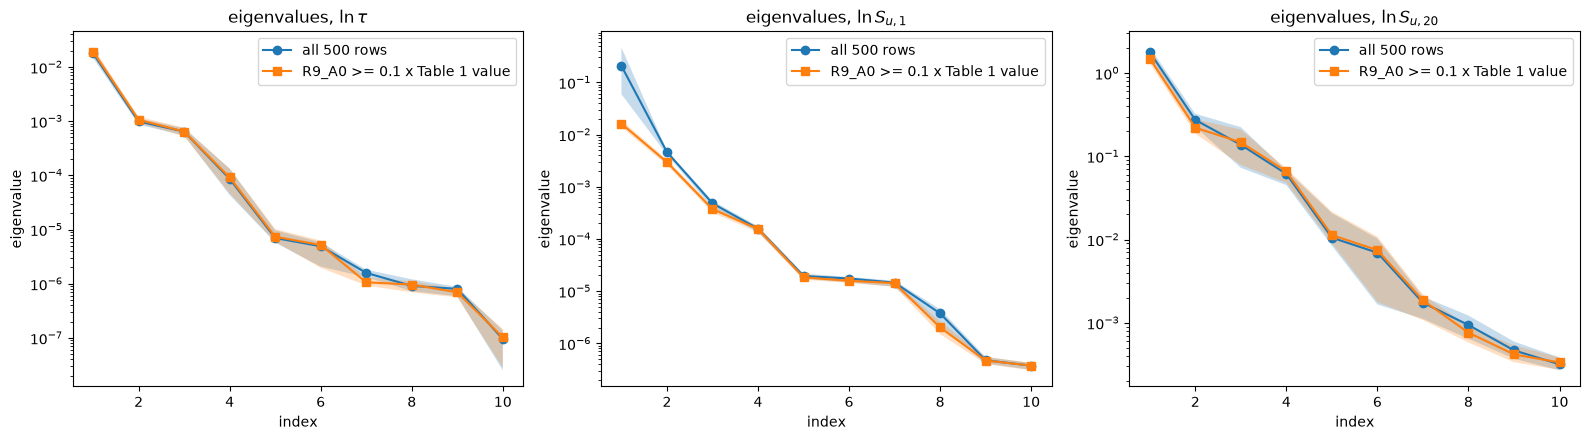

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for j, q in enumerate(QOIS):
    for lab, s, mk in [('all 500 rows', sub[q], 'o'), ('R9_A0 >= 0.1 x Table 1 value', sub_c[(0.1, q)], 's')]:
        lam, B = s.eigenvalues[:10], s.bootstrap_eigenvalues[:, :10]
        lo, hi = np.percentile(B, [2.5, 97.5], axis=0)
        k = np.arange(1, 11)
        axes[j].semilogy(k, lam, mk + '-', label=lab)
        axes[j].fill_between(k, lo, hi, alpha=0.25)
    axes[j].set_xlabel('index'); axes[j].set_ylabel('eigenvalue'); axes[j].set_title(f'eigenvalues, {QLAB[q]}')
    axes[j].legend()
fig.tight_layout(); plt.close(fig)
fig

With the tail removed (c = 0.1) the bootstrap band of ln Su1 narrows and its λ1 is 0.0162 instead of 0.206, with a first gap λ1/λ2 = 5.5; the spectra of ln τ and ln Su20 are nearly unchanged.

### Choice of dimension

- **ln τ: n = 1.** λ1/λ2 = 18.1 (bootstrap interval [14.8, 21.9]) with no second gap (λ2/λ3 = 1.5, interval [1.3, 1.9]), a stable $\mathbf w_1$ (distance 0.021), LOO R² 0.9182 for a quadratic in $y_1$ against 0.9471 in two variables; the result is unchanged when the `R9_A0` tail is removed. A third gap, λ3/λ4 = 7.5, makes a three-dimensional subspace well defined too (distance 0.049 at k = 3), but its second and third directions are not separated from each other and together lie within the left-out share of 0.088 at n = 1.
- **ln Su1: n = 2.** λ2/λ3 = 9.6 (interval [8.6, 11.1]; the intervals of λ2 and λ3 are separated), the two-dimensional subspace is stable (distance 0.026), λ1 + λ2 carry 0.997 of the trace, and a quadratic in $(y_1, y_2)$ raises LOO R² from 0.6972 to 0.9266. This holds with the tail removed (λ2/λ3 = 8.0; LOO R² 0.800 to 0.962). The gap rule's n = 1 rests on λ1/λ2 = 44.7, which a few rows near `R9_A0` = 0 set (interval [14.0, 99.9]; 5.5 without the tail), so it is not used for the choice.
- **ln Su20: n = 1.** λ1/λ2 = 6.5 (interval [5.5, 7.7]) with no second gap (λ2/λ3 = 2.0), a stable $\mathbf w_1$ (distance 0.029) and a poorly determined $\mathbf w_2$ (distance 0.121); a quadratic in $y_1$ reaches LOO R² 0.8788. A quadratic in $(y_1, y_2)$ fits better (0.9362), and the left-out share at n = 1 is the largest of the three (0.217): the rest of the variation of ln Su20 is spread over several weak, poorly separated directions, of which the second has eigenvalue 0.273 against λ1 = 1.782. A fourth gap, λ4/λ5 = 5.8, bounds a four-dimensional subspace (distance 0.041 at k = 4) whose directions 2 to 4 are not separated from one another (λ2/λ3 = 2.0, λ3/λ4 = 2.2; distances 0.121 and 0.152 at k = 2 and 3).

### Comparison with the paper

The paper reports no active subspaces; it samples the posterior, not the prior, at 91 experimental conditions that are not those used here. The quantities below are therefore context, compared qualitatively.

In [14]:
for q in QOIS:
    v = val[q][ok]
    act = ac.activity_scores(sub[q], n=1) / sub[q].eigenvalues.sum()
    w2 = sub2[q].W[:, 1]
    print(f'{q:5s}: prior coefficient of variation {v.std(ddof=1) / v.mean():.3f}, sd of ln q {np.log(v).std(ddof=1):.3f}; '
          f'activity score / trace R9_Ainf {act[iR["R9_Ainf"]]:.1e}, X1_A {act[iR["X1_A"]]:.1e}, '
          f'R9_eff_He {act[iR["R9_eff_He"]]:.1e}; w2 components R10_A {w2[iR["R10_A"]]:+.3f}, R11_A {w2[iR["R11_A"]]:+.3f}')
print(f'R15_Ainf prior mean {hd.PRIOR_MEAN[13]:.3e} (Table 1 value {hd.NOMINAL[13]:.2e}, bounds 5e11:1e12)')

tau  : prior coefficient of variation 0.133, sd of ln q 0.115; activity score / trace R9_Ainf 4.4e-04, X1_A 2.4e-05, R9_eff_He 0.0e+00; w2 components R10_A -0.250, R11_A -0.018
Su1  : prior coefficient of variation 0.121, sd of ln q 0.130; activity score / trace R9_Ainf 3.4e-07, X1_A 9.2e-07, R9_eff_He 7.1e-27; w2 components R10_A -0.510, R11_A +0.722
Su20 : prior coefficient of variation 1.222, sd of ln q 0.956; activity score / trace R9_Ainf 1.4e-04, X1_A 1.5e-06, R9_eff_He 1.6e-15; w2 components R10_A -0.016, R11_A +0.013
R15_Ainf prior mean 7.565e+11 (Table 1 value 2.00e+12, bounds 5e11:1e12)


| quantity | paper (preprint page) | this notebook |
|---|---|---|
| number of uncertain inputs | 31 (Sec. 2.2, p. 5; Table 1, p. 6) | 31 |
| prior | independent Gaussians, mean = sd = Table 1 value, truncated to L:U (p. 5) | same; 500 Monte Carlo draws |
| sampling | affine-invariant MCMC of the posterior [5], 64 walkers, 1.5 × 10$^4$ steps, 9.6 × 10$^5$ samples (p. 7) | prior only |
| quantities of interest | 91 experiments: 77 flame speeds, 6 flow reactors, 8 ignition delays (p. 5) | 1 ignition delay, 2 flame speeds at conditions chosen here |
| eigenvalues, eigenvectors | not reported | ln τ and ln Su20 one-dimensional (λ1/λ2 = 18.1 and 6.5); ln Su1 two-dimensional (λ2/λ3 = 9.6; its λ1/λ2 = 44.7 is set by the `R9_A0` tail) |
| R9 high-pressure A "not constrained by the data" (p. 11) | posterior broad, near uniform | activity score / trace of `R9_Ainf`: 4.4e-04, 3.4e-07, 1.4e-04: these QoIs barely depend on it either |
| X1 A, "to a lesser degree" (p. 11) | posterior broad | activity score / trace of `X1_A`: 2.4e-05, 9.2e-07, 1.5e-06 |
| R10 and R11 A factors (IDs 8, 9): positive posterior correlation (p. 11) | "a constraint on the relative flux through these competing pathways" | ln Su1 $\mathbf w_2$: `R10_A` −0.510, `R11_A` +0.722, a contrast of the two, which is what a positive correlation needs; in ln τ's $\mathbf w_1$ they have the same sign (−0.109, −0.135) |
| R9 He and H$_2$O efficiencies (IDs 7, 4): negative correlation (p. 11) | negative correlation (7, 4): the net rate of R9 "can be maintained" by either third body (p. 11) | not testable here: the three mixtures contain no He, and the activity score of `R9_eff_He` is at most of order 1e-15 of the trace |
| propagation: 2-D lean flame kernel (H$_2$/air, 20 atm, φ = 0.4; p. 11), net product with sd below 2 % (abstract, p. 1) | posterior | not comparable (prior, 1-D flame): the prior coefficient of variation of Su20 is 1.222 |

### References

1. J. Bell, M. Day, J. Goodman, R. Grout, M. Morzfeld. A Bayesian approach to calibrating hydrogen flame kinetics using many experiments and parameters. *Combustion and Flame* 205 (2019) 305–315. [doi:10.1016/j.combustflame.2019.04.023](https://doi.org/10.1016/j.combustflame.2019.04.023) (preprint read: arXiv:1803.03500v1).
2. M. P. Burke, M. Chaos, Y. Ju, F. L. Dryer, S. J. Klippenstein. Comprehensive H$_2$/O$_2$ kinetic model for high-pressure combustion. *International Journal of Chemical Kinetics* 44(7) (2012) 444–474. [doi:10.1002/kin.20603](https://doi.org/10.1002/kin.20603)
3. X. You, A. Packard, M. Frenklach. Process informatics tools for predictive modeling: Hydrogen combustion. *International Journal of Chemical Kinetics* 44(2) (2012) 101–116. [doi:10.1002/kin.20627](https://doi.org/10.1002/kin.20627)
4. S. G. Davis, A. V. Joshi, H. Wang, F. Egolfopoulos. An optimized kinetic model of H$_2$/CO combustion. *Proceedings of the Combustion Institute* 30(1) (2005) 1283–1292. [doi:10.1016/j.proci.2004.08.252](https://doi.org/10.1016/j.proci.2004.08.252)
5. J. Goodman, J. Weare. Ensemble samplers with affine invariance. *Communications in Applied Mathematics and Computational Science* 5(1) (2010) 65–80. [doi:10.2140/camcos.2010.5.65](https://doi.org/10.2140/camcos.2010.5.65)
6. P. G. Constantine. *Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*. SIAM, 2015. [doi:10.1137/1.9781611973860](https://doi.org/10.1137/1.9781611973860)
7. D. G. Goodwin, H. K. Moffat, I. Schoegl, R. L. Speth, B. W. Weber. Cantera: An object-oriented software toolkit for chemical kinetics, thermodynamics, and transport processes, version 3.2.0. https://www.cantera.org
8. PelePhysics (AMReX-Combustion), `Mechanisms/BurkeDryer`, https://github.com/AMReX-Combustion/PelePhysics (source of the mechanism file; BSD-3-Clause).

### Acknowledgments

From the paper (p. 15): "The work at LBNL was supported by the U.S. Department of Energy, Office of Science, Office of Advanced Scientific Computing Research, Applied Mathematics program under contract number DE-AC02005CH11231" (printed so; the contract number is DE-AC02-05CH11231 as given in the next sentence). "Part of the simulations were performed using resources of the National Energy Research Scientific Computing Center (NERSC), a DOE Office of Science User Facility supported by the Office of Science of the U.S. Department of Energy under Contract No. DE-AC02-05CH11231."

In [15]:
print(f'Total run time: {time.perf_counter() - t_start:.1f} s')

Total run time: 15.6 s
